In [1]:
from requirements import *

# Figure 2


In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)

## Figures 2b-e: see DUNE_script.ipynb

## Figure 2g. Nearest-neighbour enrichment z-score, Control vs MDS (split-triangle heatmap, all cell types)


In [4]:
remove_samples = ['region2_0042591', 'region2_0078981', 'region1_0078989', 'region4_0065604'] # sparse samples

enrichment_di_MDS = dict() 
samples = adata_xenv1.obs['sample_name'][adata_xenv1.obs['diagnosis'].isin(['MDS-LB', 'MDS-IB1', 'MDS-IB2'])].unique()
samples = [x for x in samples if not x in remove_samples]
for samp in samples:
    print(samp)
    tmp = adata_xenv1[adata_xenv1.obs['sample_name'] == samp]
    sq.gr.spatial_neighbors(tmp,n_neighs=5)
    sq.gr.nhood_enrichment(tmp, cluster_key="ct_general")
    ct_order = list(tmp.obs['ct_general'].cat.categories)
    for ct in list(tmp.obs['ct_general'].cat.categories):
        for i,score in enumerate(list(tmp.uns['ct_general_nhood_enrichment']['zscore'][list(tmp.obs['ct_general'].cat.categories).index(ct)])):
            if not (ct, ct_order[i]) in enrichment_di_MDS:
                enrichment_di_MDS[(ct, ct_order[i])] = []
            enrichment_di_MDS[(ct, ct_order[i])].append(score)

enrichment_di_control = dict() 
samples = adata_xenv1.obs['sample_name'][adata_xenv1.obs['diagnosis'].isin(['Control-Donor', 'Control-Lymph'])].unique()
samples = [x for x in samples if not x in remove_samples]
for samp in samples: 
    print(samp)
    tmp = adata_xenv1[adata_xenv1.obs['sample_name'] == samp]
    sq.gr.spatial_neighbors(tmp,n_neighs=5)
    sq.gr.nhood_enrichment(tmp, cluster_key="ct_general")
    ct_order = list(tmp.obs['ct_general'].cat.categories)
    for ct in list(tmp.obs['ct_general'].cat.categories):
        for i,score in enumerate(list(tmp.uns['ct_general_nhood_enrichment']['zscore'][list(tmp.obs['ct_general'].cat.categories).index(ct)])):
            if not (ct, ct_order[i]) in enrichment_di_control:
                enrichment_di_control[(ct, ct_order[i])] = []
            enrichment_di_control[(ct, ct_order[i])].append(score)


import statistics
ct_order = ['Erythroid','Late/Mature Myeloid','Osteoblast','Early Myeloid','Mesenchymal/Stromal',
 'Macrophage','HSPC','B Cell','T Cell','NK','pDC','Mast','Megakaryocyte','Adipocyte','Plasma Cell','Endothelial','VSMC']

tonorm = dict() # key is celltype, values are enrichment values
for ct in ct_order:
    tonorm[ct] = []
    for ct2 in ct_order:
        tonorm[ct].extend([x for x in enrichment_di_MDS[(ct, ct2)] if not np.isnan(x)])
        tonorm[ct].extend([x for x in enrichment_di_control[(ct, ct2)] if not np.isnan(x)])

sd_di = dict()
for ct in tonorm:
    sd_di[ct] = statistics.stdev(tonorm[ct])

triangle_MDS_norm2 = []
triangle_control_norm2 = []
for ct in ct_order:
    for ct2 in ct_order:
        # normalize each by SD and then take the average
        values = [x/sd_di[ct] for x in enrichment_di_MDS[(ct, ct2)] if not np.isnan(x)]
        triangle_MDS_norm2.append(sum(values)/len(values))
        values = [x/sd_di[ct] for x in enrichment_di_control[(ct, ct2)] if not np.isnan(x)]
        triangle_control_norm2.append(sum(values)/len(values))


region1_0011549


  0%|          | 0/1000 [00:00<?, ?/s]

region1_0011552


  0%|          | 0/1000 [00:00<?, ?/s]

region2_0011552


  0%|          | 0/1000 [00:00<?, ?/s]

... (102 outputs left out)

region2_0079269


  0%|          | 0/1000 [00:00<?, ?/s]

region1_0079269


  0%|          | 0/1000 [00:00<?, ?/s]

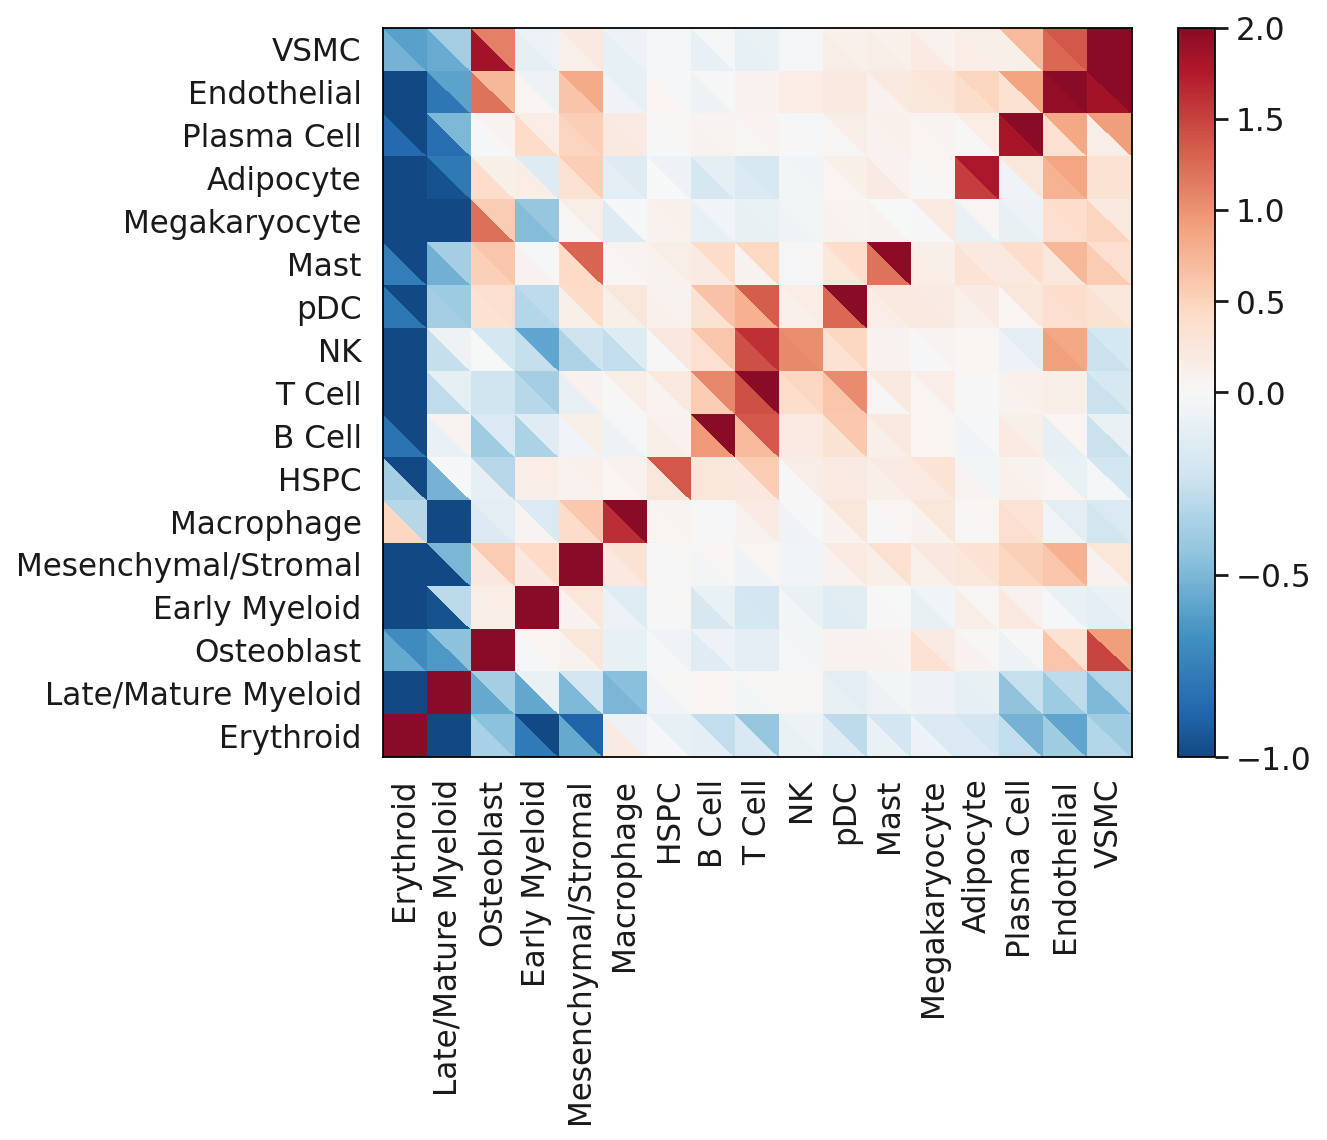

In [5]:
from matplotlib.tri import Triangulation
import matplotlib.colors as colors

sc.set_figure_params(figsize=(7.5, 6))
matplotlib.rcParams['pdf.fonttype'] = 42

M = 17
N = 17
x = np.arange(M + 1)
y = np.arange(N + 1)
xs, ys = np.meshgrid(x, y)
zs = (xs * ys) % 10
zs = zs[:-1, :-1].ravel()

triangles1 = [(i + j*(M+1), i+1 + j*(M+1), i + (j+1)*(M+1)) for j in range(N) for i in range(M)]
triangles2 = [(i+1 + j*(M+1), i+1 + (j+1)*(M+1), i + (j+1)*(M+1)) for j in range(N) for i in range(M)]
triang1 = Triangulation(xs.ravel()-0.5, ys.ravel()-0.5, triangles1)
triang2 = Triangulation(xs.ravel()-0.5, ys.ravel()-0.5, triangles2)

vmin = -1
vmax = 2
norm = colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cmap = cmr.get_sub_cmap('RdBu_r', 0.05, 0.95)

img1 = plt.tripcolor(triang1, triangle_control_norm2, cmap=cmap, norm = norm)
img2 = plt.tripcolor(triang2, triangle_MDS_norm2, cmap=cmap, norm = norm)

plt.colorbar(img1)
plt.xlim(x[0]-0.5, x[-1]-0.5)
plt.ylim(y[0]-0.5, y[-1]-0.5)
plt.xticks(x[:-1], ct_order, rotation=90)
plt.yticks(y[:-1], ct_order) 
plt.show()
